### Initial Tests

Contains tests for:
- loading data
- verify uninterpolated model with AM data

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from ozone import Ozone, utils

model_data_path = '/Users/namsonnguyen/repo/data/AM_Data/SON50_w_opacity/'
#freq_range = (210, 240)
my_ozone = Ozone(model_data_path)#, freq_range=freq_range)

freq_channels = my_ozone.am_model.freq_map
freq_mask = my_ozone.am_model.freq_mask

idx=5
nscale_map = my_ozone.am_model.lognscale_map
lognscale = nscale_map[idx]
print(f'Log Nscale: {lognscale}')

airmass_map = my_ozone.am_model.logairmass_map
logairmass = airmass_map[idx]
print(f'Log Airmass: {logairmass}')

am_data = np.load(f'/Users/namsonnguyen/repo/data/AM_Data/SON50_w_opacity/MaunaKea_Tb_Spectrum_{logairmass:.3f}_+{lognscale:.3f}.out')

#                            (1643.44 um_pwv)   (2658.58 um_pwv)  

2.110218730801302
Log Nscale: 0.25
Log Airmass: 0.801


## dTb_pwv
---

Issue: The deviation is 0 with or without the log to linear conversion factor

Solution: Switched to field map idx 5 because idx 4 resulted in lognscale == 1

---

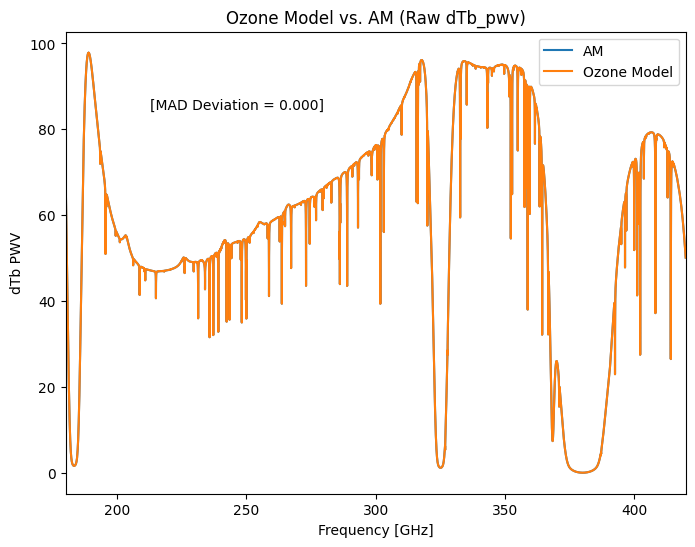

In [23]:
AM_dTb_pwv = am_data[freq_mask,6] * utils.log_to_linear_nscale_factor(lognscale)
model_dTb_pwv = my_ozone.am_model.Tb.nscale.jacobian[idx,idx]

plt.figure(figsize=(8, 6))
deviation = ((model_dTb_pwv - AM_dTb_pwv) / AM_dTb_pwv) * 100
max_deviation = np.percentile(deviation, 99)
plt.figtext(0.23, 0.75, f'[MAD Deviation = {np.median(np.abs(deviation)):.3f}]')

plt.plot(
    freq_channels,
    AM_dTb_pwv,
    label="AM"
)

plt.plot(
    freq_channels,
    model_dTb_pwv,
    label="Ozone Model"
)

plt.legend()

plt.title(f'Ozone Model vs. AM (Raw dTb_pwv)')
plt.xlabel(f'Frequency [GHz]')
plt.ylabel(f'dTb PWV')
freq_range = my_ozone.freq_range
plt.xlim(freq_range)

assert max_deviation < 1.0
assert np.median(np.abs(deviation)) < 0.1


## dTb_zenith_angle

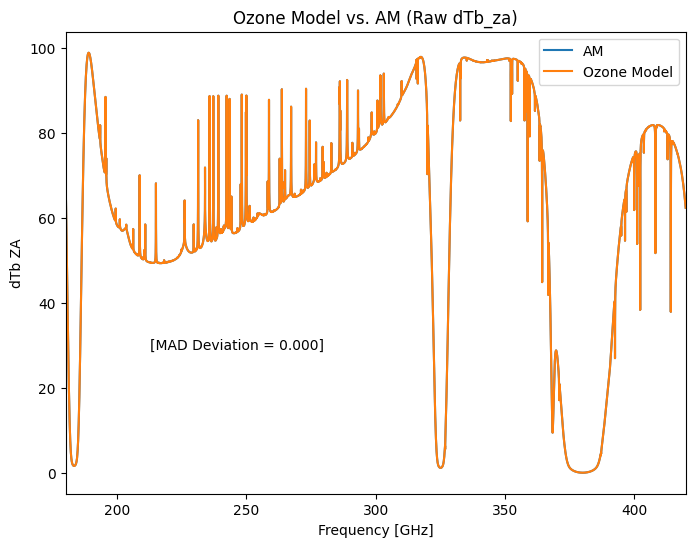

In [22]:
AM_dTb_zenith_angle = am_data[freq_mask,5] * utils.log_to_linear_airmass_factor(logairmass)
model_dTb_zenith_angle = my_ozone.am_model.Tb.airmass.jacobian[idx,idx]

plt.figure(figsize=(8, 6))
deviation = ((model_dTb_zenith_angle - AM_dTb_zenith_angle) / AM_dTb_zenith_angle) * 100
max_deviation = np.percentile(deviation, 99)
plt.figtext(0.23, 0.35, f'[MAD Deviation = {np.median(np.abs(deviation)):.3f}]')

plt.plot(
    freq_channels,
    AM_dTb_zenith_angle,
    label="AM"
)

plt.plot(
    freq_channels,
    model_dTb_zenith_angle,
    label="Ozone Model"
)

plt.legend()

plt.title(f'Ozone Model vs. AM (Raw dTb_za)')
plt.xlabel(f'Frequency [GHz]')
plt.ylabel(f'dTb ZA')
freq_range = my_ozone.freq_range
plt.xlim(freq_range)

assert max_deviation < 1.0
assert np.median(np.abs(deviation)) < 0.1
